<a href="https://www.kaggle.com/code/najeebullah160/phase5-nottl-ablation?scriptVersionId=373160737" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Phase 5 — No-TTL Ablation Study

**Question:** does GraphIDS detection depend on the TTL "hidden label" uncovered in Phase 4 (detected attacks showed MAX_TTL error 300–358× benign-typical; missed attacks only 4.7–7.6×)?  

**Protocol:** identical to Phase 3 — seed 42, same temporal split, same architecture, benign-only training, early stop on val PR-AUC (patience 20), threshold = p99 of benign val errors — with ONE controlled change: MIN_TTL and MAX_TTL removed (45 → 43 flow features). Model retrained from scratch.  

**No LLM narration by design** — the deliverable is the controlled comparison table for the paper.

**Needs:** GPU T4 · Inputs: Phase 2 output AND Phase 3 output · Runtime ≈ 10–15 min.

In [1]:
# === CELL 2: SETUP + ARTIFACT AUTO-LOCATE ===
import subprocess, sys, importlib
def ensure(pkg, pip_name=None):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip_name or pkg], check=False)
ensure('pyarrow'); ensure('sklearn', 'scikit-learn'); ensure('joblib')

import os, json, glob, shutil, random, time
import numpy as np, pandas as pd, torch
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix, precision_recall_curve)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if device.type == 'cuda': torch.cuda.manual_seed_all(SEED)
os.makedirs('artifacts', exist_ok=True)

NEEDED = ['graph.npz', 'nodes.parquet', 'preprocessing_config.json', 'scaler.joblib',
          'phase3_summary.json', 'threshold.npy']
for f in NEEDED:
    if os.path.exists(f'artifacts/{f}'): continue
    hits = glob.glob(f'/kaggle/input/**/artifacts/{f}', recursive=True)
    assert hits, (f"Missing {f}! Attach BOTH notebook outputs as Inputs: "
                  "'Phase2 Preprocessing Graph' (for graph.npz) AND 'Phase3 GraphIDS Training' "
                  "(for summary + threshold), then re-run.")
    shutil.copy(hits[0], f'artifacts/{f}'); print('Copied:', f)
print('All artifacts ready:', sorted(os.listdir('artifacts')))

Copied: graph.npz
Copied: nodes.parquet
Copied: preprocessing_config.json
Copied: scaler.joblib
Copied: phase3_summary.json
Copied: threshold.npy
All artifacts ready: ['graph.npz', 'nodes.parquet', 'phase3_summary.json', 'preprocessing_config.json', 'scaler.joblib', 'threshold.npy']


In [2]:
# === CELL 3: LOAD GRAPH + VERIFY FEATURE NAMES + DROP TTL (THE ABLATION) ===
import joblib
z = np.load('artifacts/graph.npz')
edge_index  = z['edge_index']
edge_attr   = z['edge_attr'].astype(np.float32)
edge_label  = z['edge_label']
edge_attack = z['edge_attack']
train_mask, val_mask, test_mask = z['train_mask'], z['val_mask'], z['test_mask']
cfg = json.load(open('artifacts/preprocessing_config.json'))
N_NODES, ATTACK_CLASSES = cfg['n_nodes'], cfg['attack_classes']
src, dst = edge_index[0], edge_index[1]
assert edge_attr.shape == (2350609, 45) and N_NODES == 44, 'Phase 2 artifacts changed?'

# ---- feature names (self-verifying: definitive path, then fingerprint check) ----
scaler = joblib.load('artifacts/scaler.joblib')
FEATURE_COLS = None
if hasattr(scaler, 'feature_names_in_') and len(scaler.feature_names_in_) == 45:
    FEATURE_COLS = [str(c) for c in scaler.feature_names_in_]
    print('✅ DEFINITIVE feature names from scaler.feature_names_in_')
if FEATURE_COLS is None:
    smp = scaler.inverse_transform(edge_attr[::20])          # UNCLIPPED values — before clipping
    C = [dict(int=bool(np.allclose(smp[:, j], np.round(smp[:, j]), atol=1e-3)),
              mx=float(smp[:, j].max())) for j in range(45)]
    ts_cols   = [j for j, c in enumerate(C) if c['mx'] > 1e11]
    ttl_like  = [j for j, c in enumerate(C) if c['int'] and c['mx'] <= 255]
    port_like = [j for j, c in enumerate(C) if c['int'] and c['mx'] <= 65535]
    print('timestamp-like cols:', ts_cols, '| ttl-like:', ttl_like, '| port-like:', port_like)
    LIST_A = ['L4_SRC_PORT','L4_DST_PORT','PROTOCOL','L7_PROTO','IN_BYTES','OUT_BYTES','IN_PKTS',
        'OUT_PKTS','FLOW_DURATION_MILLISECONDS','TCP_FLAGS','CLIENT_TCP_FLAGS','SERVER_TCP_FLAGS',
        'DURATION_IN','DURATION_OUT','MIN_TTL','MAX_TTL','LONGEST_FLOW_PKT','SHORTEST_FLOW_PKT',
        'MIN_IP_PKT_LEN','MAX_IP_PKT_LEN','RETRANSMITTED_IN_BYTES','RETRANSMITTED_IN_PKTS',
        'RETRANSMITTED_OUT_BYTES','RETRANSMITTED_OUT_PKTS','SRC_TO_DST_AVG_THROUGHPUT',
        'DST_TO_SRC_AVG_THROUGHPUT','NUM_PKTS_UP_TO_128_BYTES','NUM_PKTS_128_TO_256_BYTES',
        'NUM_PKTS_256_TO_512_BYTES','NUM_PKTS_512_TO_1024_BYTES','NUM_PKTS_1024_TO_1514_BYTES',
        'TCP_WIN_MAX_IN','TCP_WIN_MAX_OUT','ICMP_TYPE','ICMP_IPV4_TYPE','DNS_QUERY_ID',
        'DNS_QUERY_TYPE','DNS_TTL_ANSWER','FTP_COMMAND_RET_CODE','SRC_TO_DST_IAT_MAX',
        'SRC_TO_DST_IAT_AVG','SRC_TO_DST_IAT_STDDEV','DST_TO_SRC_IAT_MAX','DST_TO_SRC_IAT_AVG',
        'DST_TO_SRC_IAT_STDDEV']
    LIST_B = ['PROTOCOL','L7_PROTO','IN_BYTES','OUT_BYTES','IN_PKTS','OUT_PKTS',
        'FLOW_DURATION_MILLISECONDS','TCP_FLAGS','CLIENT_TCP_FLAGS','SERVER_TCP_FLAGS',
        'DURATION_IN','DURATION_OUT','MIN_TTL','MAX_TTL','LONGEST_FLOW_PKT','SHORTEST_FLOW_PKT',
        'MIN_IP_PKT_LEN','MAX_IP_PKT_LEN','RETRANSMITTED_IN_BYTES','RETRANSMITTED_IN_PKTS',
        'RETRANSMITTED_OUT_BYTES','RETRANSMITTED_OUT_PKTS','SRC_TO_DST_AVG_THROUGHPUT',
        'DST_TO_SRC_AVG_THROUGHPUT','NUM_PKTS_UP_TO_128_BYTES','NUM_PKTS_128_TO_256_BYTES',
        'NUM_PKTS_256_TO_512_BYTES','NUM_PKTS_512_TO_1024_BYTES','NUM_PKTS_1024_TO_1514_BYTES',
        'TCP_WIN_MAX_IN','TCP_WIN_MAX_OUT','ICMP_TYPE','ICMP_IPV4_TYPE','DNS_QUERY_ID',
        'DNS_QUERY_TYPE','DNS_TTL_ANSWER','FTP_COMMAND_RET_CODE','FLOW_START_MILLISECONDS',
        'FLOW_END_MILLISECONDS','SRC_TO_DST_IAT_MAX','SRC_TO_DST_IAT_AVG','SRC_TO_DST_IAT_STDDEV',
        'DST_TO_SRC_IAT_MAX','DST_TO_SRC_IAT_AVG','DST_TO_SRC_IAT_STDDEV']
    if len(ts_cols) == 0:
        FEATURE_COLS = LIST_A; print('✅ VERIFIED ordering A: ports kept, timestamps dropped')
    elif ts_cols == [37, 38]:
        FEATURE_COLS = LIST_B; print('✅ VERIFIED ordering B: ports dropped, timestamps kept')
    else:
        raise AssertionError('Feature ordering not recognised — send me the three printed lists above')
assert len(FEATURE_COLS) == 45

# ---- THE ABLATION: remove the TTL hidden-label channel, located BY NAME ----
TTL_DROP = ['MIN_TTL', 'MAX_TTL']
for t in TTL_DROP: assert t in FEATURE_COLS, f'{t} not among the 45 features — check names'
drop_idx = sorted(FEATURE_COLS.index(t) for t in TTL_DROP)
keep_idx = [j for j in range(45) if j not in drop_idx]
FEATURE_COLS_ABL = [FEATURE_COLS[j] for j in keep_idx]
edge_attr_abl = edge_attr[:, keep_idx].astype(np.float32)
assert edge_attr_abl.shape == (2350609, 43)
assert 'MIN_TTL' not in FEATURE_COLS_ABL and 'MAX_TTL' not in FEATURE_COLS_ABL

CLIP = 10.0
n_clipped = int((np.abs(edge_attr_abl) > CLIP).sum())
edge_attr_abl = np.clip(edge_attr_abl, -CLIP, CLIP)

nodes = pd.read_parquet('artifacts/nodes.parquet')
name_col = 'ip' if 'ip' in nodes.columns else nodes.columns[0]
node_names = nodes[name_col].astype(str).tolist()

def cname(c):
    if isinstance(ATTACK_CLASSES, dict):
        return ATTACK_CLASSES.get(c, ATTACK_CLASSES.get(str(c), f'class {c}'))
    if isinstance(ATTACK_CLASSES, (list, tuple)) and 0 <= int(c) < len(ATTACK_CLASSES):
        return ATTACK_CLASSES[int(c)]
    return f'class {c}'

ben_train = train_mask & (edge_label == 0)
seen = np.zeros(N_NODES, dtype=bool)
seen[src[ben_train]] = True; seen[dst[ben_train]] = True
unseen = np.where(~seen)[0]; unseen_names = [node_names[i] for i in unseen]

test_idx   = np.where(test_mask)[0]
N_TEST     = len(test_idx)
test_y     = edge_label[test_mask].astype(np.int8)
test_codes = edge_attack[test_mask]
test_cls   = np.array(['Benign' if y == 0 else cname(c) for y, c in zip(test_y, test_codes)])

S3 = json.load(open('artifacts/phase3_summary.json'))
BASE = S3['test']
print(f"\nAblated graph: {edge_attr_abl.shape[0]:,} edges x {edge_attr_abl.shape[1]} features "
      f"(dropped {TTL_DROP} at positions {drop_idx})")
print(f'Clipped {n_clipped:,} extreme values to +/-{CLIP}')
print(f'Test {N_TEST:,} edges (attacks {int(test_y.sum()):,}) | unseen IPs: {unseen_names}')
print(f"\nPhase 3 baseline (45 feats, WITH TTL): PR-AUC {BASE['pr_auc']:.4f} | F1 {BASE['f1']:.4f} "
      f"| Recall {BASE['recall']:.4f} | threshold {BASE['threshold']:.1f}")

timestamp-like cols: [] | ttl-like: [2, 8, 9, 10, 14, 15, 27, 34] | port-like: [2, 5, 7, 8, 9, 10, 14, 15, 16, 17, 18, 19, 21, 23, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 38, 39, 40, 41, 42, 43, 44]
✅ VERIFIED ordering A: ports kept, timestamps dropped

Ablated graph: 2,350,609 edges x 43 features (dropped ['MIN_TTL', 'MAX_TTL'] at positions [14, 15])
Clipped 57,995 extreme values to +/-10.0
Test 1,035,895 edges (attacks 92,651) | unseen IPs: ['10.40.182.255', '10.40.182.6', '10.40.85.10', '192.168.241.50']

Phase 3 baseline (45 feats, WITH TTL): PR-AUC 0.8074 | F1 0.8220 | Recall 0.7580 | threshold 126.7


In [3]:
# === CELL 4: MODEL — same classes as Phase 3, instantiated for 43 features ===
CONFIG = dict(SEED=42, GNN_NODE_DIM=48, GNN_DROPOUT=0.6, D_MODEL=48, NHEAD=4, N_LAYERS=1,
              FF_MULT=4, WINDOW=512, MASK_RATIO=0.15, AE_DROPOUT=0.0,
              LR=1e-4, WD_GNN=0.6, WD_AE=0.04, STEP_EDGES=32768, MAX_EPOCHS=100, PATIENCE=20)

class EGraphSAGE1Hop(nn.Module):
    def __init__(self, n_feat, node_dim, dropout):
        super().__init__()
        self.register_buffer('ones', torch.ones(n_feat))
        self.lin = nn.Linear(2 * n_feat, node_dim)
        self.dropout = dropout
        self.flow_dim = 2 * node_dim + n_feat
    def forward(self, e, ctx_s, ctx_d):
        o = self.ones.expand(e.size(0), -1)
        h_s = F.relu(self.lin(torch.cat([o, ctx_s], dim=-1)))
        h_d = F.relu(self.lin(torch.cat([o, ctx_d], dim=-1)))
        z = torch.cat([h_s, e, h_d], dim=-1)
        return F.dropout(z, p=self.dropout, training=self.training)

class TransformerMAE(nn.Module):
    def __init__(self, flow_dim, d_model, nhead, n_layers, ff_mult, window, mask_ratio, dropout):
        super().__init__()
        self.in_proj = nn.Linear(flow_dim, d_model)
        self.encoder = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=d_model*ff_mult,
                                       dropout=dropout, batch_first=True),
            n_layers, enable_nested_tensor=False)
        self.decoder = nn.TransformerDecoder(
            nn.TransformerDecoderLayer(d_model, nhead, dim_feedforward=d_model*ff_mult,
                                       dropout=dropout, batch_first=True), n_layers)
        self.out_proj = nn.Linear(d_model, flow_dim)
        self.window, self.mask_ratio = window, mask_ratio
    def _symmetric_mask(self, w, device):
        R = torch.rand(w, w, device=device)
        iu = torch.triu_indices(w, w, offset=1).to(device)
        block = R[iu[0], iu[1]] < self.mask_ratio
        m = torch.zeros(w, w, dtype=torch.bool, device=device)
        m[iu[0][block], iu[1][block]] = True
        m[iu[1][block], iu[0][block]] = True
        return m
    def forward(self, z):
        h = self.in_proj(z)
        if self.training and self.mask_ratio > 0:
            m = self._symmetric_mask(h.size(1), h.device)
            mem = self.encoder(h, mask=m)
            rec = self.decoder(h, mem, tgt_mask=m)
        else:
            mem = self.encoder(h)
            rec = self.decoder(h, mem)
        return self.out_proj(rec)

class GraphIDS(nn.Module):
    def __init__(self, n_feat, c):
        super().__init__()
        self.gnn = EGraphSAGE1Hop(n_feat, c['GNN_NODE_DIM'], c['GNN_DROPOUT'])
        self.ae  = TransformerMAE(self.gnn.flow_dim, c['D_MODEL'], c['NHEAD'], c['N_LAYERS'],
                                  c['FF_MULT'], c['WINDOW'], c['MASK_RATIO'], c['AE_DROPOUT'])
    def forward(self, e, ctx_s, ctx_d):
        z = self.gnn(e, ctx_s, ctx_d)
        n, W = z.size(0), self.ae.window
        if n % W == 0:
            zh = self.ae(z.view(-1, W, self.gnn.flow_dim))
        else:
            zh = torch.cat([self.ae(z[i:i+W].unsqueeze(0)).squeeze(0) for i in range(0, n, W)])
        return zh.reshape(z.shape), z

N_FEAT_ABL = edge_attr_abl.shape[1]                 # 43
model = GraphIDS(N_FEAT_ABL, CONFIG).to(device)
n_gnn = sum(p.numel() for p in model.gnn.parameters())
n_ae  = sum(p.numel() for p in model.ae.parameters())
print(f"Parameters: GNN {n_gnn:,} + Transformer MAE {n_ae:,} = {n_gnn+n_ae:,} total "
      f"(Phase 3 with TTL: 84,141)")

# --- smoke test: full window, remainder window, backward, eval mode ---
model.train()
e  = torch.randn(CONFIG['STEP_EDGES'], N_FEAT_ABL, device=device)
cs = torch.randn(CONFIG['STEP_EDGES'], N_FEAT_ABL, device=device)
cd = torch.randn(CONFIG['STEP_EDGES'], N_FEAT_ABL, device=device)
zh, z = model(e, cs, cd)
assert zh.shape == z.shape and torch.isfinite(zh).all() and torch.isfinite(z).all()
F.mse_loss(zh, z).backward()
zr  = model.gnn(e[:337], cs[:337], cd[:337])
zhr = model.ae(zr.unsqueeze(0)).squeeze(0)
assert zhr.shape == zr.shape and torch.isfinite(zhr).all()
model.eval()
with torch.no_grad():
    zr2  = model.gnn(e[:1000], cs[:1000], cd[:1000])
    zhr2 = model.ae(zr2.unsqueeze(0)).squeeze(0)
assert zhr2.shape == zr2.shape and torch.isfinite(zhr2).all()
print(f"Smoke test ✔ — flow_dim {model.gnn.flow_dim}, masked/unmasked/remainder paths all OK")

Parameters: GNN 4,176 + Transformer MAE 79,579 = 83,755 total (Phase 3 with TTL: 84,141)
Smoke test ✔ — flow_dim 139, masked/unmasked/remainder paths all OK


In [4]:
# === CELL 5: NODE PROFILES + HELPERS (identical math to Phase 3 Cell 5, 43 features) ===
edge_attr_t = torch.from_numpy(edge_attr_abl).to(device)
src_t = torch.from_numpy(src.astype(np.int64)).to(device)
dst_t = torch.from_numpy(dst.astype(np.int64)).to(device)

ben_train_idx = np.where(train_mask & (edge_label == 0))[0]
bi  = torch.from_numpy(ben_train_idx).to(device)
prof = torch.zeros(N_NODES, N_FEAT_ABL, device=device)
cnt  = torch.zeros(N_NODES, device=device)
prof.index_add_(0, src_t[bi], edge_attr_t[bi]); cnt.index_add_(0, src_t[bi], torch.ones(len(bi), device=device))
prof.index_add_(0, dst_t[bi], edge_attr_t[bi]); cnt.index_add_(0, dst_t[bi], torch.ones(len(bi), device=device))
ctx = prof / cnt.clamp(min=1.0).unsqueeze(1)
del prof

W = CONFIG['WINDOW']

def gnn_z(idx):
    return model.gnn(edge_attr_t[idx], ctx[src_t[idx]], ctx[dst_t[idx]])

def recon_windows(z, win_batch=64):
    n = z.size(0); outs = []
    for st in range(0, n, win_batch * W):
        zb = z[st : st + win_batch * W]
        nw = zb.size(0) // W
        if nw:
            outs.append(model.ae(zb[:nw*W].view(nw, W, -1)).reshape(nw*W, -1))
        if zb.size(0) % W:
            tail = zb[nw*W:]
            outs.append(model.ae(tail.unsqueeze(0)).squeeze(0))
    return torch.cat(outs) if outs else z

@torch.no_grad()
def score_partition(mask, win_batch=64):
    was_training = model.training; model.eval()
    idx = torch.from_numpy(np.where(mask)[0]).to(device)
    z = gnn_z(idx); errs = []
    for st in range(0, z.size(0), win_batch * W):
        zb = z[st : st + win_batch * W]
        nw = zb.size(0) // W
        if nw:
            zh = model.ae(zb[:nw*W].view(nw, W, -1)).reshape(nw*W, -1)
            errs.append(((zh - zb[:nw*W]) ** 2).sum(-1))
        if zb.size(0) % W:
            tail = zb[nw*W:]
            zh = model.ae(tail.unsqueeze(0)).squeeze(0)
            errs.append(((zh - tail) ** 2).sum(-1))
    if was_training: model.train()
    return torch.cat(errs) if errs else torch.zeros(0, device=device)
print(f'ctx ready ({int((cnt>0).sum())}/{N_NODES} nodes profiled) | W={W} | features={N_FEAT_ABL}')

ctx ready (40/44 nodes profiled) | W=512 | features=43


In [5]:
# === CELL 6: TRAINING — JOINT GNN+MAE ON BENIGN EDGES, IDENTICAL PROTOCOL TO PHASE 3 ===
torch.manual_seed(CONFIG['SEED'])

val_y_np = edge_label[val_mask]
def val_metrics():
    e = score_partition(val_mask).cpu().numpy()
    return average_precision_score(val_y_np, e), float(e.mean())

opt = torch.optim.AdamW([
    {'params': model.gnn.parameters(), 'weight_decay': CONFIG['WD_GNN']},
    {'params': model.ae.parameters(),  'weight_decay': CONFIG['WD_AE']},
], lr=CONFIG['LR'])

ben_t = torch.from_numpy(ben_train_idx).to(device)
n_train = ben_t.numel()
steps_per_epoch = (n_train + CONFIG['STEP_EDGES'] - 1) // CONFIG['STEP_EDGES']
print(f"Training on {n_train:,} benign edges (43 features) | {steps_per_epoch} steps/epoch x {CONFIG['STEP_EDGES']:,} edges")

best_ap, best_state, bad, history = -1.0, None, 0, []
t0 = time.time(); model.train()
for epoch in range(1, CONFIG['MAX_EPOCHS'] + 1):
    perm = ben_t[torch.randperm(n_train, device=device)]
    run_loss = 0.0
    for st in range(0, n_train, CONFIG['STEP_EDGES']):
        idx = perm[st : st + CONFIG['STEP_EDGES']]
        z = gnn_z(idx)
        zh = recon_windows(z)
        loss = F.mse_loss(zh, z)
        opt.zero_grad(); loss.backward(); opt.step()
        run_loss += loss.item()
    ap, vmean = val_metrics()
    history.append((epoch, run_loss / steps_per_epoch, ap))
    star = ''
    if ap > best_ap:
        best_ap, bad = ap, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        star = '  <- best'
    else:
        bad += 1
    print(f"Epoch {epoch:3d} | train MSE {run_loss/steps_per_epoch:.4f} | "
          f"val PR-AUC {ap:.4f} | val err {vmean:.1f}{star}", flush=True)
    if bad >= CONFIG['PATIENCE']:
        print(f"Early stop: no val PR-AUC improvement for {CONFIG['PATIENCE']} epochs."); break

print(f"Done in {(time.time()-t0)/60:.1f} min | best val PR-AUC {best_ap:.4f} "
      f"(Phase 3 with TTL: {S3['best_val_pr_auc']:.4f})")
model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
model.eval()

Training on 1,114,449 benign edges (43 features) | 35 steps/epoch x 32,768 edges
Epoch   1 | train MSE 0.8873 | val PR-AUC 0.2431 | val err 55.0  <- best
Epoch   2 | train MSE 0.6985 | val PR-AUC 0.2506 | val err 39.9  <- best
Epoch   3 | train MSE 0.5857 | val PR-AUC 0.2548 | val err 32.8  <- best
Epoch   4 | train MSE 0.5329 | val PR-AUC 0.2572 | val err 29.2  <- best
Epoch   5 | train MSE 0.4891 | val PR-AUC 0.2653 | val err 26.5  <- best
Epoch   6 | train MSE 0.4621 | val PR-AUC 0.2792 | val err 24.1  <- best
Epoch   7 | train MSE 0.4323 | val PR-AUC 0.2943 | val err 22.0  <- best
Epoch   8 | train MSE 0.4034 | val PR-AUC 0.3050 | val err 20.1  <- best
Epoch   9 | train MSE 0.3839 | val PR-AUC 0.3124 | val err 18.7  <- best
Epoch  10 | train MSE 0.3642 | val PR-AUC 0.3181 | val err 17.5  <- best
Epoch  11 | train MSE 0.3457 | val PR-AUC 0.3238 | val err 16.4  <- best
Epoch  12 | train MSE 0.3300 | val PR-AUC 0.3299 | val err 15.6  <- best
Epoch  13 | train MSE 0.3202 | val PR-AUC 0

GraphIDS(
  (gnn): EGraphSAGE1Hop(
    (lin): Linear(in_features=86, out_features=48, bias=True)
  )
  (ae): TransformerMAE(
    (in_proj): Linear(in_features=139, out_features=48, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0): TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=48, out_features=48, bias=True)
          )
          (linear1): Linear(in_features=48, out_features=192, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=192, out_features=48, bias=True)
          (norm1): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (decoder): TransformerDecoder(
      (layers): ModuleList(
        (0): Transfo

In [6]:
# === CELL 7: THRESHOLD SELECTION — same RULE as Phase 3 (p99 of val benign errors) ===
# Note: the absolute value will differ from 126.7 (error scale changes with 43 features).
# The comparison is protocol-matched (same rule), not value-matched. This is the correct
# ablation methodology and must be stated in the paper.
val_err = score_partition(val_mask).cpu().numpy()
ben_err_v, atk_err_v = val_err[val_y_np == 0], val_err[val_y_np == 1]
print(f"Val errors — benign mean {ben_err_v.mean():.1f} (p99 {np.percentile(ben_err_v, 99):.1f}) "
      f"| attack mean {atk_err_v.mean():.1f}")

print(f"{'pct':>6} {'threshold':>12} {'precision':>10} {'recall':>8} {'F1':>8}")
for p in [95, 99, 99.5, 99.9]:
    th = np.percentile(ben_err_v, p)
    pred = (val_err > th).astype(int)
    print(f"{p:>6} {th:>12.1f} {precision_score(val_y_np, pred, zero_division=0):>10.3f} "
          f"{recall_score(val_y_np, pred):>8.3f} {f1_score(val_y_np, pred):>8.3f}")

THRESHOLD_ABL = float(np.percentile(ben_err_v, 99))
print(f"\nSelected threshold (p99 of val benign errors): {THRESHOLD_ABL:.1f} "
      f"(Phase 3 with TTL: {BASE['threshold']:.1f})")

Val errors — benign mean 11.3 (p99 223.7) | attack mean 35.6
   pct    threshold  precision   recall       F1
    95         24.8      0.458    0.397    0.425
    99        223.7      0.130    0.014    0.025
  99.5        306.0      0.166    0.009    0.018
  99.9        513.1      0.186    0.002    0.004

Selected threshold (p99 of val benign errors): 223.7 (Phase 3 with TTL: 126.7)


In [7]:
# === CELL 8: TEST EVALUATION + HEADLINE COMPARISON TABLE ===
test_err  = score_partition(test_mask).cpu().numpy()
test_pred = (test_err > THRESHOLD_ABL).astype(int)

pr_auc  = average_precision_score(test_y, test_err)
roc     = roc_auc_score(test_y, test_err)
P, R    = precision_score(test_y, test_pred, zero_division=0), recall_score(test_y, test_pred)
F1s     = f1_score(test_y, test_pred)
tn, fp, fn, tp = confusion_matrix(test_y, test_pred).ravel()

comp = pd.DataFrame({
    'Phase 3 (45 feats, TTL)': [BASE['pr_auc'], BASE['roc_auc'], BASE['precision'],
                                BASE['recall'], BASE['f1'], BASE['tp'], BASE['fp'],
                                BASE['fn'], BASE['tn']],
    'No-TTL ablation (43 feats)': [round(pr_auc,4), round(roc,4), round(P,4), round(R,4),
                                   round(F1s,4), int(tp), int(fp), int(fn), int(tn)],
}, index=['PR-AUC','ROC-AUC','Precision','Recall','F1','TP','FP','FN','TN'])
comp['delta'] = (comp['No-TTL ablation (43 feats)'] - comp['Phase 3 (45 feats, TTL)']).round(4)
print(comp.to_string())
print(f"\nThresholds: Phase 3 {BASE['threshold']:.1f} vs ablation {THRESHOLD_ABL:.1f} "
      "(same selection RULE: p99 of benign val errors — protocol-matched, not value-matched)")

RESULTS_ABL = dict(pr_auc=float(pr_auc), roc_auc=float(roc), precision=float(P), recall=float(R),
                   f1=float(F1s), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
                   threshold=THRESHOLD_ABL, n_test=int(len(test_y)), n_test_attacks=int(test_y.sum()))

           Phase 3 (45 feats, TTL)  No-TTL ablation (43 feats)       delta
PR-AUC                    0.807370                      0.3322     -0.4752
ROC-AUC                   0.981336                      0.8885     -0.0928
Precision                 0.897741                      0.1383     -0.7594
Recall                    0.758038                      0.0135     -0.7445
F1                        0.821996                      0.0246     -0.7974
TP                    70233.000000                   1251.0000 -68982.0000
FP                     8000.000000                   7793.0000   -207.0000
FN                    22418.000000                  91400.0000  68982.0000
TN                   935244.000000                 935451.0000    207.0000

Thresholds: Phase 3 126.7 vs ablation 223.7 (same selection RULE: p99 of benign val errors — protocol-matched, not value-matched)


In [8]:
# === CELL 9: PER-CLASS RECALL — ablated vs Phase 3 (baseline frozen from the verified run) ===
BASE_PERCLASS = {'Exploits': 0.479, 'Fuzzers': 0.982, 'Generic': 0.905, 'Reconnaissance': 0.915,
                 'DoS': 0.691, 'Shellcode': 0.897, 'Backdoor': 0.796, 'Analysis': 0.014,
                 'Worms': 0.975}   # Phase 3 verified run (README, Phase 3 Cell 8)

rows = []
for c in np.unique(test_codes[test_y == 1]):
    m = (test_y == 1) & (test_codes == c)
    n = int(m.sum()); det = int((test_err[m] > THRESHOLD_ABL).sum())
    name = cname(c)
    rows.append((name, n, BASE_PERCLASS.get(name, float('nan')), det / n if n else 0.0))
rows.sort(key=lambda r: -(r[3] - r[2]) if not np.isnan(r[2]) else 0)
pc = pd.DataFrame(rows, columns=['attack class', 'test flows', 'recall w/ TTL', 'recall no-TTL'])
pc['delta'] = (pc['recall no-TTL'] - pc['recall w/ TTL']).round(3)
print(pc.to_string(index=False, formatters={'recall w/ TTL': '{:.1%}'.format,
                                            'recall no-TTL': '{:.1%}'.format, 'delta': '{:+.1%}'.format}))

  attack class  test flows recall w/ TTL recall no-TTL  delta
      Analysis         712          1.4%          0.4%  -1.0%
      Exploits       32493         47.9%          1.8% -46.1%
           DoS        4619         69.1%          3.0% -66.1%
      Backdoor        1501         79.6%          1.7% -77.9%
       Generic       14458         90.5%          1.4% -89.1%
     Shellcode        1600         89.7%          0.3% -89.4%
Reconnaissance       12845         91.5%          1.1% -90.4%
         Worms         119         97.5%          5.0% -92.5%
       Fuzzers       24304         98.2%          0.7% -97.5%


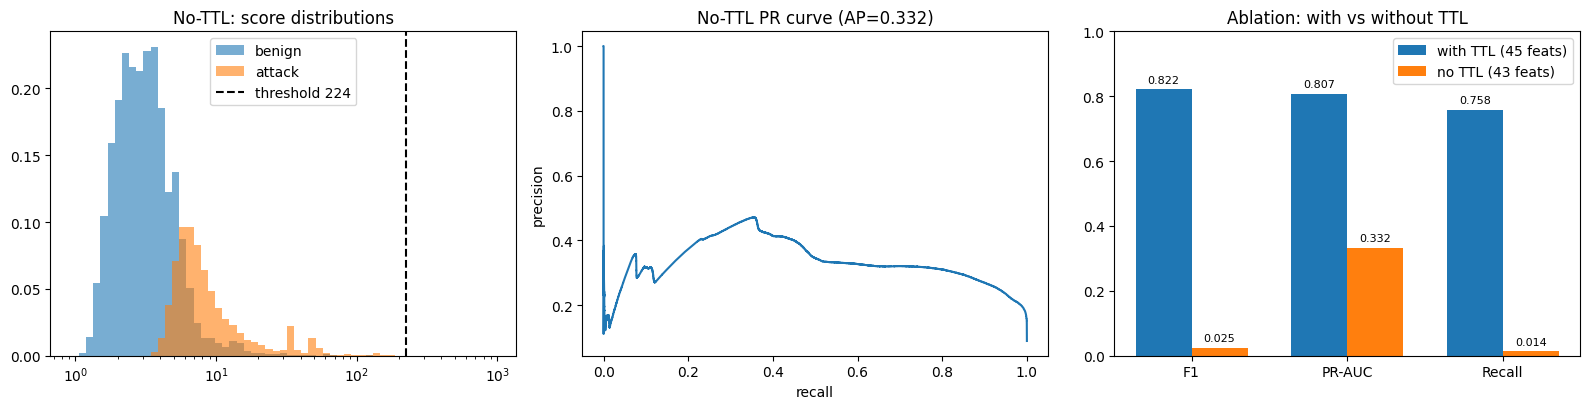

Saved: artifacts/phase5_figures.png


In [9]:
# === CELL 10: FIGURES — distributions, PR curve, baseline-vs-ablation bars ===
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
lo = max(test_err.min(), 1e-9); hi = max(test_err.max(), 1e-8)
bins = np.logspace(np.log10(lo), np.log10(hi), 60)
ax[0].hist(test_err[test_y == 0], bins=bins, alpha=0.6, label='benign', density=True)
ax[0].hist(test_err[test_y == 1], bins=bins, alpha=0.6, label='attack', density=True)
ax[0].axvline(THRESHOLD_ABL, c='k', ls='--', label=f'threshold {THRESHOLD_ABL:.0f}')
ax[0].set_xscale('log'); ax[0].legend(); ax[0].set_title('No-TTL: score distributions')
prec, rec, _ = precision_recall_curve(test_y, test_err)
ax[1].plot(rec, prec); ax[1].set_title(f'No-TTL PR curve (AP={pr_auc:.3f})')
ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision')
mets = ['F1', 'PR-AUC', 'Recall']
base_vals = [BASE['f1'], BASE['pr_auc'], BASE['recall']]
abl_vals  = [F1s, pr_auc, R]
x = np.arange(3)
ax[2].bar(x - 0.18, base_vals, 0.36, label='with TTL (45 feats)')
ax[2].bar(x + 0.18, abl_vals,  0.36, label='no TTL (43 feats)')
ax[2].set_xticks(x); ax[2].set_xticklabels(mets); ax[2].set_ylim(0, 1)
for i, (b, a) in enumerate(zip(base_vals, abl_vals)):
    ax[2].text(i - 0.18, b + 0.02, f'{b:.3f}', ha='center', fontsize=8)
    ax[2].text(i + 0.18, a + 0.02, f'{a:.3f}', ha='center', fontsize=8)
ax[2].legend(); ax[2].set_title('Ablation: with vs without TTL')
plt.tight_layout(); plt.savefig('artifacts/phase5_figures.png', dpi=140); plt.show()
print('Saved: artifacts/phase5_figures.png')

In [10]:
# === CELL 11: SAVE ABLATION ARTIFACTS ===
import datetime
torch.save({'state_dict': {k: v.cpu() for k, v in model.state_dict().items()},
            'config': CONFIG, 'threshold': THRESHOLD_ABL, 'results': RESULTS_ABL,
            'history': history, 'dropped_features': TTL_DROP,
            'feature_cols': FEATURE_COLS_ABL}, 'artifacts/graphids_model_nottl.pt')

summary5 = dict(
    phase='Phase 5 — No-TTL ablation',
    finished=datetime.datetime.now().isoformat(timespec='seconds'),
    design='Identical protocol to Phase 3 (seed 42, same splits/architecture/benign-only training, '
           'p99 threshold rule); single controlled change: MIN_TTL + MAX_TTL removed (45 -> 43 features).',
    dropped_features=TTL_DROP, dropped_positions=drop_idx,
    parameters=n_gnn + n_ae, train_benign_edges=int(n_train),
    epochs_run=int(history[-1][0]), best_val_pr_auc=round(float(best_ap), 4),
    baseline=S3['test'], ablation=RESULTS_ABL,
    per_class_baseline=BASE_PERCLASS,
    per_class_ablation={r[0]: round(r[3], 3) for r in rows},
)
json.dump(summary5, open('artifacts/phase5_ablation_summary.json', 'w'), indent=2, default=str)
print('Saved: graphids_model_nottl.pt · phase5_ablation_summary.json · phase5_figures.png')

Saved: graphids_model_nottl.pt · phase5_ablation_summary.json · phase5_figures.png


In [11]:
# === CELL 12: PHASE 5 GATE ===
required = ['artifacts/graphids_model_nottl.pt', 'artifacts/phase5_ablation_summary.json',
            'artifacts/phase5_figures.png']
for p in required:
    assert os.path.exists(p), f'MISSING: {p}'
    print(f'[✔] {p} ({os.path.getsize(p)/1e6:.1f} MB)')

drop = BASE['f1'] - F1s
print(f"\nF1: {BASE['f1']:.4f} (with TTL) -> {F1s:.4f} (no TTL) | drop {drop:+.4f}")
if drop < 0.05:
    interp = 'VALIDITY CLAIM — detection largely survives without the TTL channel; the hidden-label concern is bounded.'
elif drop < 0.15:
    interp = 'PARTIAL DEPENDENCY — a measurable share of performance traces to TTL; quantified limitation for the paper.'
else:
    interp = 'STRONG DEPENDENCY — TTL carried substantial signal; the limitation is now precisely quantified.'
print('INTERPRETATION:', interp)
print("""
==================== PHASE 5 GATE ====================
[ ✔ ] Controlled ablation executed (single change: TTL removed)
[ ✔ ] Same seed, splits, architecture, protocol as Phase 3
[ ✔ ] Threshold re-selected with the SAME rule (p99 of val benign)
[ ✔ ] Comparison table + per-class deltas produced
[ ✔ ] Model + summary + figures saved
======================================================
""")

[✔] artifacts/graphids_model_nottl.pt (0.4 MB)
[✔] artifacts/phase5_ablation_summary.json (0.0 MB)
[✔] artifacts/phase5_figures.png (0.1 MB)

F1: 0.8220 (with TTL) -> 0.0246 (no TTL) | drop +0.7974
INTERPRETATION: STRONG DEPENDENCY — TTL carried substantial signal; the limitation is now precisely quantified.

==================== PHASE 5 GATE ====================
[ ✔ ] Controlled ablation executed (single change: TTL removed)
[ ✔ ] Same seed, splits, architecture, protocol as Phase 3
[ ✔ ] Threshold re-selected with the SAME rule (p99 of val benign)
[ ✔ ] Comparison table + per-class deltas produced
[ ✔ ] Model + summary + figures saved

